# DAY1 실습 04 : AI4I 종합 복습

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)



| 컬럼 | 설명 |
|---|---|
| Type | 제품 유형 (L / M / H) |
| Air temperature [K] | 공기 온도 (켈빈) |
| Process temperature [K] | 공정 온도 (켈빈) |
| Rotational speed [rpm] | 회전속도 (분당 회전수) |
| Torque [Nm] | 토크 (뉴턴미터) |
| Tool wear [min] | 공구 마모 시간 (분) |
| Machine failure | 고장 여부 (0 : 정상, 1 : 고장) |

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

### 1. `head` / `shape` / `dtypes` : 앞 5행, 행·열 수, 열별 자료형을 확인하시오.

In [ ]:
display(data.head())
print("행·열:", data.shape)
data.dtypes

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


행·열: (10000, 14)


UDI                          int64
Product ID                     object
Type                           object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

### 2. `isna` / `duplicated` : 열별 결측값 수와 완전 중복 행 수를 구하시오.

In [ ]:
display(data.isna().sum())
print("완전 중복 행:", data.duplicated().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

완전 중복 행: 0


### 3. `value_counts` : `Type`의 빈도와 백분율(%)을 한 표로 만드시오.

In [ ]:
pd.DataFrame({
    "빈도": data["Type"].value_counts(),
    "백분율(%)": (data["Type"].value_counts(normalize=True) * 100).round(2)
})

,빈도,백분율(%)
Type,,
L,6000,60.00
M,2997,29.97
H,1003,10.03


### 4. `mode` : `Type`의 최빈값을 구하시오.

In [ ]:
data["Type"].mode()

0    L
Name: Type, dtype: object

### 5. 막대그래프 : `Type`별 빈도를 막대그래프로 그리시오. 제목과 축 이름을 넣으시오.

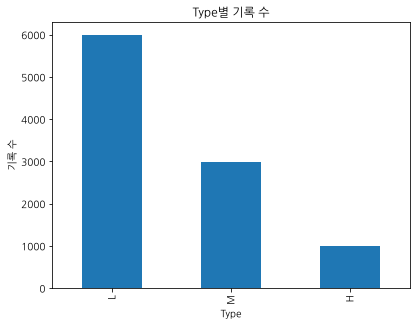

In [ ]:
data["Type"].value_counts().plot.bar()
plt.title("Type별 기록 수")
plt.xlabel("Type")
plt.ylabel("기록 수")
plt.show()

### 6. `mean` / `count` : `Machine failure`의 고장 건수와 고장률(%)을 구하시오.

In [ ]:
print("고장 건수:", data["Machine failure"].eq(1).sum())
print("고장률(%):", round(data["Machine failure"].mean() * 100, 2))

고장 건수: 339
고장률(%): 3.39


### 7. `mean` / `median` : 아래 다섯 열의 평균과 중앙값을 한 표로 만들고, 평균 − 중앙값 열을 추가하시오.

`Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]`

In [ ]:
features = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
centers = pd.DataFrame({
    "평균": data[features].mean(),
    "중앙값": data[features].median()
})
centers["평균-중앙값"] = centers["평균"] - centers["중앙값"]
centers.round(2)

,평균,중앙값,평균-중앙값
Air temperature [K],300.00,300.1,-0.10
Process temperature [K],310.01,310.1,-0.09
Rotational speed [rpm],1538.78,1503.0,35.78
Torque [Nm],39.99,40.1,-0.11
Tool wear [min],107.95,108.0,-0.05


### 8. `min` / `max` / `quantile` : `Rotational speed [rpm]`의 범위, Q1, Q3, IQR을 구하시오.

In [ ]:
speed = data["Rotational speed [rpm]"]
q1 = speed.quantile(0.25)
q3 = speed.quantile(0.75)
iqr = q3 - q1
print("범위:", speed.max() - speed.min())
print("Q1, Q3, IQR:", q1, q3, iqr)

범위: 1718
Q1, Q3, IQR: 1423.0 1612.0 189.0


### 9. `var` / `std` : `Torque [Nm]`의 분산, 표준편차(ddof=1), 변동계수(CV, %)를 구하시오.

In [ ]:
torque = data["Torque [Nm]"]
print("분산:", round(torque.var(ddof=1), 2))
print("표준편차:", round(torque.std(ddof=1), 2))
print("CV(%):", round(torque.std(ddof=1) / torque.mean() * 100, 2))

분산: 99.38
표준편차: 9.97
CV(%): 24.93


### 10. `describe` : 7번의 다섯 열을 `describe()`로 한 번에 요약하시오.

In [ ]:
features = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
data[features].describe().round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


### 11. 히스토그램 : `Rotational speed [rpm]`의 히스토그램을 `bins=30`으로 그리고, 평균 위치에 빨간 점선을 그으시오.

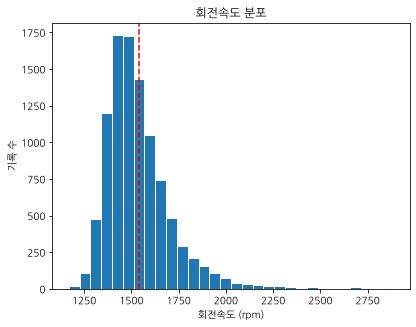

In [ ]:
plt.hist(speed, bins=30, edgecolor="white")
plt.axvline(speed.mean(), color="red", linestyle="--")
plt.title("회전속도 분포")
plt.xlabel("회전속도 (rpm)")
plt.ylabel("기록 수")
plt.show()

### 12. 박스플롯 : `Rotational speed [rpm]`의 박스플롯을 평균과 함께 그리시오.

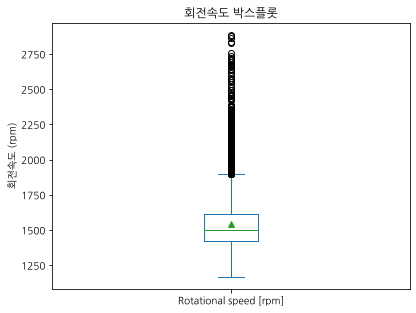

In [ ]:
speed.plot.box(showmeans=True)
plt.title("회전속도 박스플롯")
plt.ylabel("회전속도 (rpm)")
plt.show()

### 13. IQR 기준 이상값 후보 : `Rotational speed [rpm]`의 하한(Q1 − 1.5 × IQR), 상한(Q3 + 1.5 × IQR)과 경계 밖 기록 수를 구하시오.

In [ ]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
iqr_mask = (speed < lower) | (speed > upper)
print("하한, 상한:", lower, upper)
print("IQR 기준 이상값 후보:", iqr_mask.sum())

하한, 상한: 1139.5 1895.5
IQR 기준 이상값 후보: 418


### 14. z점수 : `Rotational speed [rpm]`의 z점수를 구하고 `|z| > 3`인 기록 수를 구하시오.

In [ ]:
z = (speed - speed.mean()) / speed.std(ddof=1)
print("z점수 기준 이상값 후보:", (z.abs() > 3).sum())

z점수 기준 이상값 후보: 164


### 15. `skew` / `kurt` : `Rotational speed [rpm]`와 `Torque [Nm]`의 왜도와 초과첨도를 구하시오.

In [ ]:
pd.DataFrame({
    "왜도": data[["Rotational speed [rpm]", "Torque [Nm]"]].skew(),
    "초과첨도": data[["Rotational speed [rpm]", "Torque [Nm]"]].kurt()
}).round(3)

,왜도,초과첨도
Rotational speed [rpm],1.993,7.393
Torque [Nm],-0.010,-0.013
